# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages 

In [ ]:
from aitlas.datasets import DeepGlobeRoadExtractionDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 6226


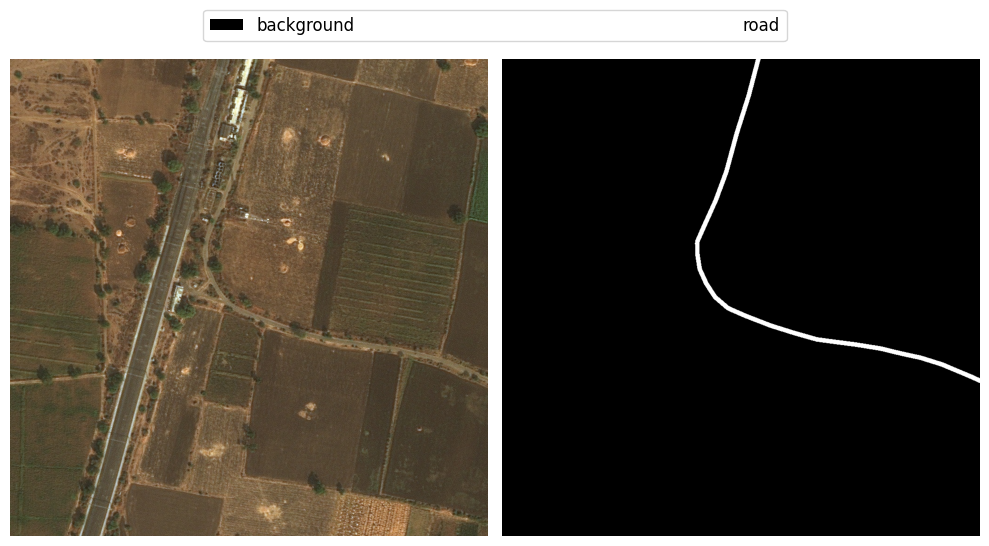

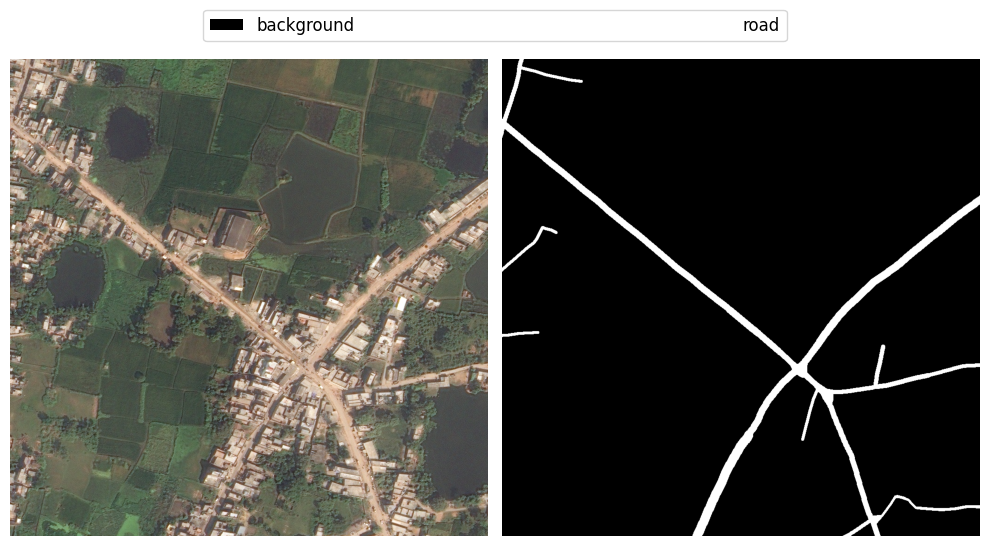

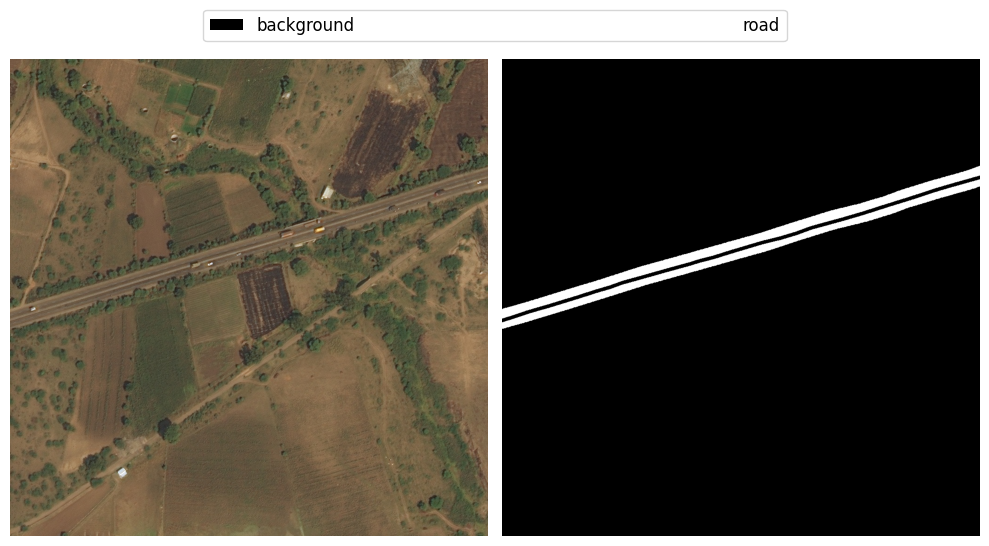

In [ ]:
dataset_config = {
    "data_dir": "./data/deepglobe_road/train"
}
dataset = DeepGlobeRoadExtractionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [5]:
dataset.data_distribution_table()

,Number of pixels
background,6.251793e+09
road,2.766401e+08


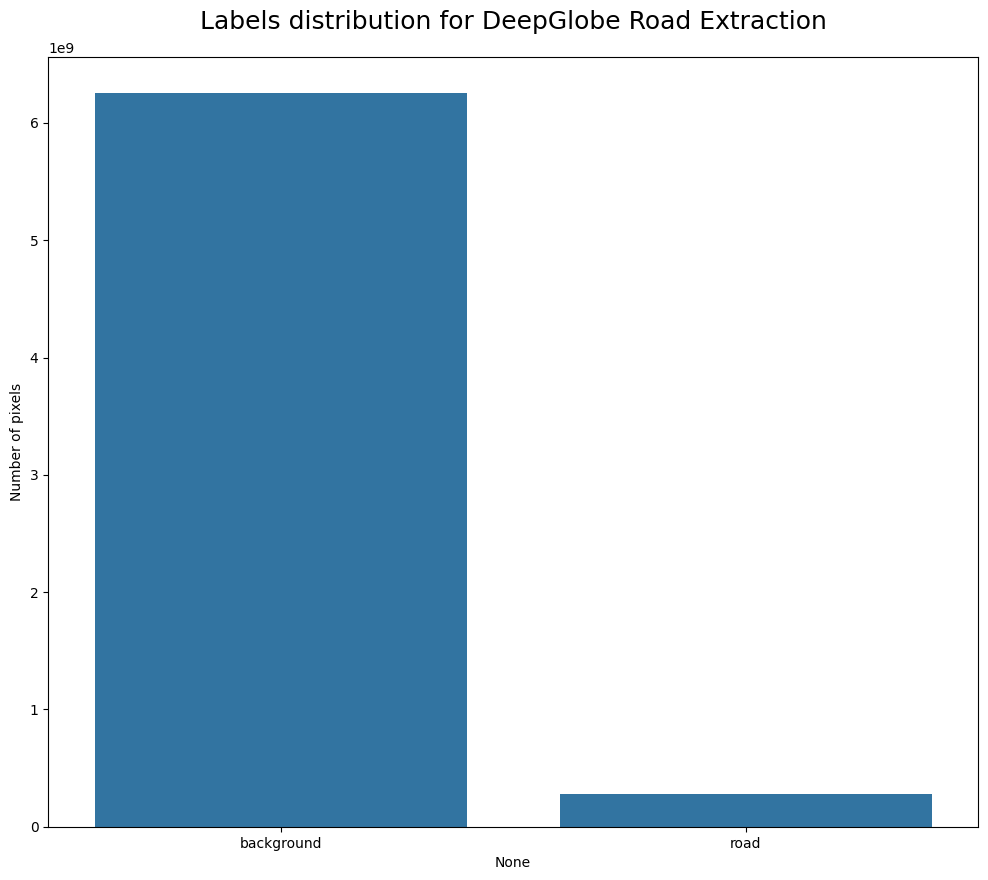

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/deepglobe_road/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = DeepGlobeRoadExtractionDataset(train_dataset_config)
len(train_dataset)

6226

## Create the model

In [ ]:
epochs = 5
model_directory = "./data/deepglobe_road"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-24 07:55:22,959 INFO Starting training.
training: 100%|██████████| 779/779 [2:23:12<00:00, 11.03s/it]
2025-03-24 10:18:35,315 INFO epoch: 1, time: 8592, loss:  0.16814
testing on train set: 100%|██████████| 779/779 [2:23:50<00:00, 11.08s/it]  
2025-03-24 12:42:27,567 INFO IOU:0.9169887057174192, IOU mean:0.48732556120378556, IOU per Class:[0.93138217 0.04326895]
training: 100%|██████████| 779/779 [2:23:17<00:00, 11.04s/it]
2025-03-24 15:05:45,151 INFO epoch: 2, time: 8598, loss:  0.04975
testing on train set: 100%|██████████| 779/779 [2:23:58<00:00, 11.09s/it]  
2025-03-24 17:29:43,550 INFO IOU:0.9196975803483318, IOU mean:0.5434224002783165, IOU per Class:[0.93399883 0.15284597]
training: 100%|██████████| 779/779 [2:23:05<00:00, 11.02s/it]
2025-03-24 19:52:49,481 INFO epoch: 3, time: 8586, loss:  0.04303
testing on train set: 100%|██████████| 779/779 [2:23:22<00:00, 11.04s/it]  
2025-03-24 22:16:11,506 INFO IOU:0.9216200262864301, IOU mean:0.5913166355674041, IOU per Class:[0.

## Predictions

2025-03-25 07:50:39,608 INFO Loading checkpoint /home/dragik/data/FAIR_EO/deepglobe_road/checkpoint.pth.tar
2025-03-25 07:50:40,665 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/deepglobe_road/checkpoint.pth.tar at epoch 6


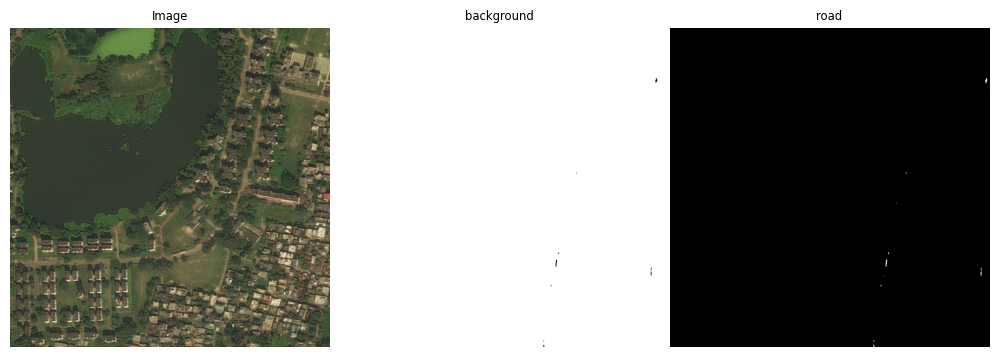

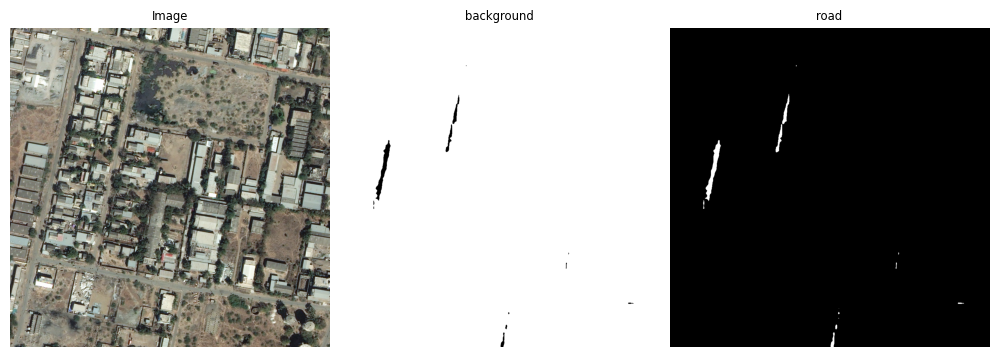

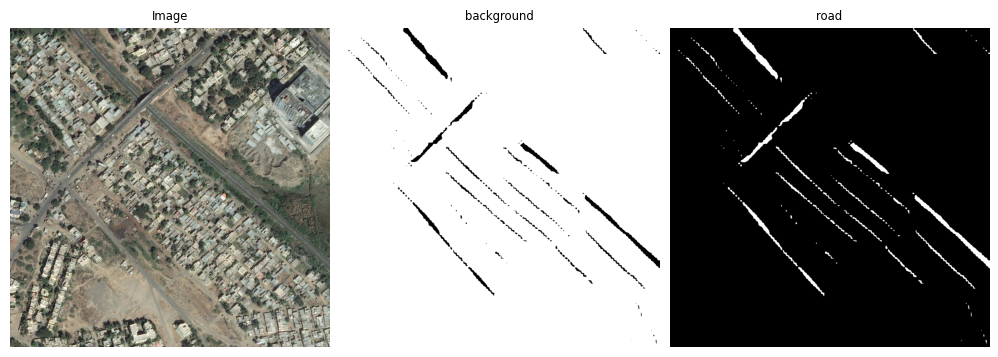

In [ ]:
model_path = "./data/deepglobe_road/checkpoint.pth.tar"
labels = ["background","road"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('./data/deepglobe_road/test/images/206_sat.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/deepglobe_road/test/images/2704_sat.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/deepglobe_road/test/images/27393_sat.jpg')
fig = model.predict_masks(image, labels, transform)